# Финальный экзамен по курсу «Анализ данных в Python»

**Российская экономическая школа, программа ФИБ**  
**Тема:** анализ данных матчей плей-офф NHL сезона 2025/2026  
**Работу выполнил:** Седов Виталий  
**Дата:** 24 октября 2026 года

### 1. Прочитать данные Excel в pandas
### Идея решения:

Одна строка файла соответствует событию матча.
Первый столбец содержит сохранённый индекс, поэтому читаем его
через `index_col=0`. Проверяем размер таблицы и уникальность событий.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font="DejaVu Sans")
Path("figures").mkdir(exist_ok=True)

events = pd.read_excel("NHL-playoffs-2026.xlsx", index_col=0)

print(events.shape)
display(events.iloc[:10, [2, 3, 4, 9, 12]])

assert events.shape == (29710, 38)
assert not events.duplicated(["Game ID", "Play ID"]).any()

(29710, 38)


,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


### Результат и интерпретация

Получено **29 710 строк и 38 столбцов**, как в PDF.
Первые десять строк совпали с примером.
Дубликатов пары `Game ID` и `Play ID` нет.

Число строк показывает количество событий, а не матчей.

### 2. Собрать таблицу игр
### Идея решения:

Группируем события по идентификатору игры.
Максимальное значение накопленного счёта является итоговым.
Число овертаймов равно числу периодов сверх первых трёх.

Дополнительно проверяем счёт независимым подсчётом событий `goal`.

In [2]:
games = events.groupby("Game ID").agg(**{
    "Date": ("Date", "first"),
    "Away Team": ("Away Team", "first"),
    "Home Team": ("Home Team", "first"),
    "Away Score": ("Cumulated Away Score", "max"),
    "Home Score": ("Cumulated Home Score", "max"),
    "Max Period": ("Period", "max"),
})

games["Overtimes"] = (games.pop("Max Period") - 3).clip(lower=0)
games["Outcome"] = games["Overtimes"].map(
    lambda n: "Final" if n == 0
    else "Final/OT" if n == 1
    else f"Final/{n}OT"
)

goals = events.loc[events["Play Type"].eq("goal")].copy()

for side in ["Away", "Home"]:
    counted = (
        goals.loc[
            goals["Team Making the Play"].eq(goals[f"{side} Team"])
        ]
        .groupby("Game ID").size()
        .reindex(games.index, fill_value=0)
    )
    assert games[f"{side} Score"].equals(counted)

display(games)

,Date,Away Team,Home Team,Away Score,Home Score,Overtimes,Outcome
Game ID,,,,,,,
2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,3,4,0,Final
2025030112,2026-04-21,Boston Bruins,Buffalo Sabres,4,2,0,Final
2025030113,2026-04-23,Buffalo Sabres,Boston Bruins,3,1,0,Final
2025030114,2026-04-26,Buffalo Sabres,Boston Bruins,6,1,0,Final
2025030115,2026-04-28,Boston Bruins,Buffalo Sabres,2,1,1,Final/OT
...,...,...,...,...,...,...,...
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,1,Final/OT
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,2,Final/2OT
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,0,Final


### Результат и интерпретация

В наборе **82 матча**. В **22** потребовались овертаймы,
максимальное число овертаймов — **2**.

Все итоговые счета совпали с независимым подсчётом голов.

### 3. Написать функцию gameInfo(gameId)
### Идея решения

Получаем строку таблицы по ID и собираем описание матча.
Сначала выводим хозяев, затем гостей. Счёт выводим в том же порядке.

In [3]:
def gameInfo(gameId):
    row = games.loc[gameId]
    return (
        f"{row['Home Team']} - {row['Away Team']} "
        f"({row['Home Score']} - {row['Away Score']}, "
        f"{row['Outcome']}, {row['Date']})"
    )

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


### Результат и интерпретация

Получены строки:

- Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
- Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)

Обе строки совпадают с контрольными примерами.
Функция возвращает текст, пригодный для таблиц и заголовков.

### 4. Найти описательные статистики общего числа голов
### Идея решения

Складываем голы обеих команд в каждой игре.
Применяем `describe`, чтобы получить среднее, разброс и квантили.

In [4]:
games["Total Score"] = games["Away Score"] + games["Home Score"]
display(games["Total Score"].describe())

count    82.000000
mean      5.926829
std       2.259578
min       1.000000
25%       5.000000
50%       6.000000
75%       7.000000
max      15.000000
Name: Total Score, dtype: float64

### Результат и интерпретация

Число матчей — **82**, среднее — **5.927**, стандартное отклонение —
**2.260**, минимум — **1**, первый квартиль — **5**, медиана — **6**,
третий квартиль — **7**, максимум — **15**.


### 5. Построить гистограмму результативности
### Идея решения

Число голов принимает целые значения.
Высота столбца показывает число матчей с соответствующим результатом.
На оси оставляем также значения с нулевой частотой.

,Число матчей
Total Score,
1,2
2,1
3,9
4,5
5,19
6,16
7,16
8,5
9,5


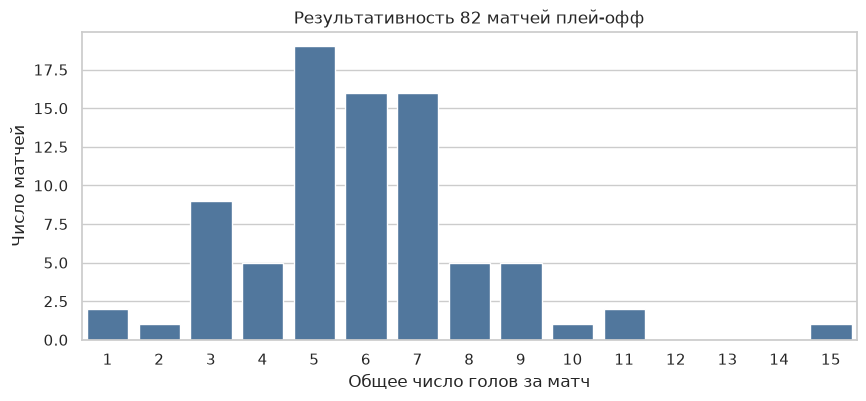

In [5]:
score_counts = (
    games["Total Score"].value_counts()
    .reindex(range(1, 16), fill_value=0)
    .sort_index()
)
display(score_counts.rename("Число матчей").to_frame())

plt.figure(figsize=(10, 4))
sns.countplot(
    x=games["Total Score"], order=range(1, 16), color="#4477aa"
)
plt.xlabel("Общее число голов за матч")
plt.ylabel("Число матчей")
plt.title("Результативность 82 матчей плей-офф")
plt.savefig("figures/05_total_goals.svg", bbox_inches="tight")
plt.show()

### Результат и интерпретация

Самый частый результат — **5 голов**, он встретился **19 раз**.
Медиана равна 6 голам. Редкий матч с 15 голами образует правый хвост
и увеличивает среднее.

Сумма частот равна **82**: каждый матч учтён один раз.

### 6. Найти самые нерезультативные и результативные игры
### Идея решения

Отбираем все строки с минимальным и максимальным общим счётом.
Фильтрация позволяет сохранить несколько игр с одинаковым результатом.

In [6]:
low_ids = games.index[
    games["Total Score"].eq(games["Total Score"].min())
]
high_ids = games.index[
    games["Total Score"].eq(games["Total Score"].max())
]

print("Минимум:")
for gid in low_ids:
    print(gameInfo(gid))

print("Максимум:")
for gid in high_ids:
    print(gameInfo(gid))

Минимум:
Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)
Максимум:
Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)


### Результат и интерпретация

Минимум — **1 гол**:

- Montréal Canadiens — Tampa Bay Lightning: **0:1**, OT, 01.05.2026.
- Philadelphia Flyers — Pittsburgh Penguins: **1:0**, OT, 29.04.2026.

Максимум — **15 голов**:

- Colorado Avalanche — Minnesota Wild: **9:6**, 03.05.2026.


### 7. Посчитать уникальных участников матчей, включая вратарей
### Идея решения

Объединим поля игроков на льду и вратарей обеих команд.
Удалим пропуски и повторяющиеся пары «игра — игрок».

Это исключит двойной счёт вратаря, который может одновременно
находиться в шестёрке на льду и в отдельном вратарском поле.

In [7]:
onice = [
    f"{side} Team's Player on the Ice #{i}"
    for side in ["Away", "Home"]
    for i in range(1, 7)
]
goalie_cols = ["Away Team's Goalie", "Home Team's Goalie"]
roster_cols = onice + goalie_cols

appearances = (
    events[["Game ID"] + roster_cols]
    .melt(id_vars="Game ID", value_name="Player")
    .dropna(subset=["Player"])
    [["Game ID", "Player"]]
    .drop_duplicates()
)

player_counts = appearances.groupby("Game ID").size()
maximum = player_counts[player_counts.eq(player_counts.max())]

for gid, count in maximum.items():
    print(gameInfo(gid), "— игроков:", count)

# Проверяем, как получается контрольное значение 41.
sample = events.loc[events["Game ID"].eq(2025030216), roster_cols]
values = pd.unique(sample.to_numpy().ravel())
print("Вместе с NaN:", len(values))
print("Только непустые имена:", pd.notna(values).sum())

# Поимённый состав матча с максимальным числом участников.
roster_rows = []
for side in ["Away", "Home"]:
    columns = [f"{side} Team's Player on the Ice #{i}" for i in range(1, 7)]
    columns += [f"{side} Team's Goalie"]
    match = events.loc[events["Game ID"].eq(maximum.index[0])]
    names = pd.unique(match[columns].to_numpy().ravel())
    for name in sorted(names[pd.notna(names)]):
        roster_rows.append({"Team": match[f"{side} Team"].iloc[0], "Player": name})
roster_audit = pd.DataFrame(roster_rows)
display(roster_audit)
display(roster_audit.groupby("Team").size().rename("Player Count"))


Montréal Canadiens - Buffalo Sabres (3 - 8, Final, 2026-05-16) — игроков: 40
Вместе с NaN: 41
Только непустые имена: 40


,Team,Player
0,Buffalo Sabres,Alex Lyon
1,Buffalo Sabres,Alex Tuch
2,Buffalo Sabres,Beck Malenstyn
3,Buffalo Sabres,Bowen Byram
4,Buffalo Sabres,Conor Timmins
5,Buffalo Sabres,Jack Quinn
6,Buffalo Sabres,Jason Zucker
7,Buffalo Sabres,Jordan Greenway
8,Buffalo Sabres,Josh Doan
9,Buffalo Sabres,Josh Norris


Team
Buffalo Sabres        20
Montréal Canadiens    20
Name: Player Count, dtype: int64

### Результат и интерпретация

Максимум — **40 игроков**: Montréal Canadiens — Buffalo Sabres,
**3:8**, 16.05.2026. У каждой команды учтено по 20 человек.

В PDF для этой игры указано 41. Такое число воспроизводится,
если посчитать `NaN` отдельным уникальным значением.
После исключения пропуска остаются **40 реальных имён**.

В Notebook приведён поимённый список для проверки.

### 8. Рассчитать расстояние от броска до створа ворот
### Идея решения

Определим атакуемые ворота по команде бросающего и стороне,
которую защищают хозяева. Затем найдём расстояние до ближайшей
точки створа шириной 6 футов.

Внутри диапазона Y от -3 до 3 расстояние по Y равно нулю.
За его пределами берём расстояние до ближайшей штанги.

In [8]:
shot_types = ["goal", "shot-on-goal", "missed-shot"]
shots = events.loc[events["Play Type"].isin(shot_types)].copy()

xcol = "X Coordinate on the Ice Rink"
ycol = "Y Coordinate on the Ice Rink"

home_shot = shots["Team Making the Play"].eq(shots["Home Team"])
home_defends_left = shots["Home Team's Defending Side"].eq("left")

shots["Goal X"] = np.where(
    home_shot.eq(home_defends_left), 89, -89
)
shots["Shot Length"] = np.hypot(
    shots[xcol] - shots["Goal X"],
    (shots[ycol].abs() - 3).clip(lower=0),
)
shots["Accurate"] = shots["Play Type"].isin(["goal", "shot-on-goal"])

display(shots[["Game ID", "Play Type", "Shot Length"]].head())
display(shots[["Game ID", "Play Type", "Shot Length"]].tail())

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.206556
9,2025030111,missed-shot,12.000000
12,2025030111,missed-shot,29.410882
13,2025030111,shot-on-goal,62.169124
19,2025030111,missed-shot,52.924474


,Game ID,Play Type,Shot Length
29695,2025030416,missed-shot,54.083269
29696,2025030416,missed-shot,5.099020
29704,2025030416,goal,46.238512
29706,2025030416,missed-shot,60.926185
29707,2025030416,shot-on-goal,49.040799


### Результат и интерпретация

Рассчитаны расстояния для **7 266 бросков**.
Первые пять: **12.207, 12.000, 29.411, 62.169, 52.924 фута**.
Последние пять: **54.083, 5.099, 46.239, 60.926, 49.041 фута**.

Направление атаки определено по стороне ворот, а не по знаку
координаты броска. Это сохраняет корректные дальние расстояния.

### 9. Сравнить распределения длины точных и неточных бросков
### Идея решения

Точных и неточных бросков разное количество.
Поэтому сравниваем отдельно нормированные плотности:
площадь гистограммы каждой группы должна равняться единице.

Используем одинаковые интервалы и `common_norm=False`.
Точным считается попадание в створ, включая гол.

,size,mean,median,min,max
Shot,,,,,
missed,2643,34.013562,32.249031,0.0,185.067555
on goal,4623,36.206558,31.827661,0.0,188.215302


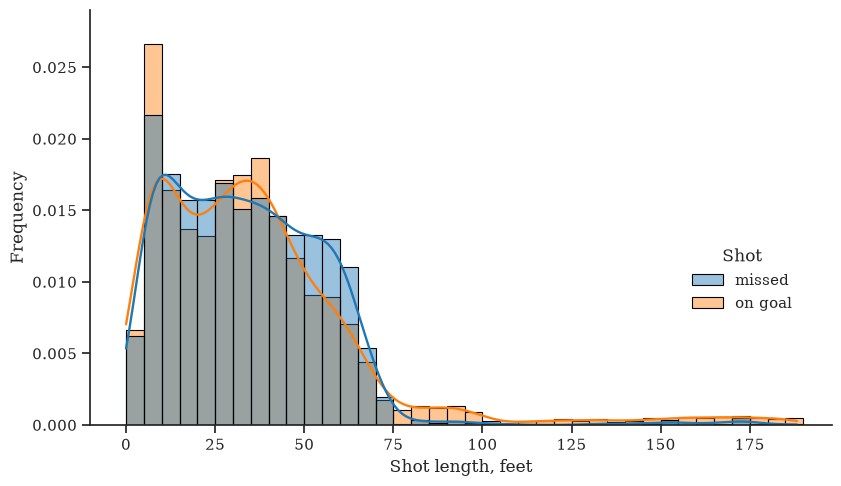

missed — площадь: 1.0
on goal — площадь: 0.9999999999999999


In [9]:
from matplotlib.ticker import FormatStrFormatter

# Английские подписи и цвета повторяют образец из условия.
shots["Shot"] = np.where(shots["Accurate"], "on goal", "missed")
display(shots.groupby("Shot")["Shot Length"].agg(
    ["size", "mean", "median", "min", "max"]
))

# Общие интервалы по 5 футов; площадь каждой группы равна единице.
bins = np.arange(0, np.ceil(shots["Shot Length"].max() / 5) * 5 + 5, 5)

# Локальный стиль действует только на этот рисунок.
with sns.axes_style("ticks"), plt.rc_context({"font.family": "DejaVu Serif"}):
    g = sns.displot(
        data=shots, x="Shot Length", hue="Shot",
        hue_order=["missed", "on goal"],
        palette={"missed": "#1f77b4", "on goal": "#ff7f0e"},
        bins=bins, stat="density", common_norm=False,
        multiple="layer", element="bars", fill=True,
        alpha=0.45, edgecolor="black", linewidth=0.8,
        kde=True, kde_kws={"cut": 0}, line_kws={"linewidth": 1.7},
        height=5, aspect=1.5,
    )
    g.set_axis_labels("Shot length, feet", "Frequency")
    g.set(xlim=(-10, 198), ylim=(0, 0.029), xticks=np.arange(0, 176, 25))
    g.ax.yaxis.set_major_formatter(FormatStrFormatter("%.3f"))
    g.ax.grid(False)
    sns.move_legend(g, "center right", bbox_to_anchor=(0.95, 0.43),
                    title="Shot", frameon=False)
    g.figure.subplots_adjust(left=0.12, right=0.98, bottom=0.14, top=0.97)
    g.savefig("figures/09_shot_density.svg", bbox_inches="tight")
    plt.show()

for label, group in shots.groupby("Shot"):
    density, edges = np.histogram(group["Shot Length"], bins=bins, density=True)
    area = np.sum(density * np.diff(edges))
    print(label, "— площадь:", area)
    assert np.isclose(area, 1)


### Результат и интерпретация

Точных бросков — **4 623**, неточных — **2 643**.
Средние расстояния — **36.21** и **34.01 фута** соответственно.
Медианы — **31.83** и **32.25 фута**.

Площади обеих гистограмм равны единице.
Среднее расстояние точных бросков увеличивает длинный правый хвост;
медианы при этом близки.

Дальние точные броски могут быть как попытками попасть в пустые
ворота, так и бросками, дошедшими до вратаря. Одной гистограммы
недостаточно, чтобы объяснить весь хвост пустыми воротами.
В Notebook эта версия дополнительно проверяется по вратарскому
контексту с учётом пропусков при решающих голах овертайма.

### 10. Найти долю точных бросков каждой команды в каждой игре
### Идея решения

Числитель — `shot-on-goal + goal`.
Знаменатель — `shot-on-goal + goal + missed-shot`.

Заблокированные броски не входят ни в числитель, ни в знаменатель.
Создаём все пары «матч — команда», чтобы не потерять нулевые значения.

In [10]:
team_games = pd.concat([
    games.reset_index()[["Game ID", "Home Team"]].rename(
        columns={"Home Team": "Team Making the Play"}
    ),
    games.reset_index()[["Game ID", "Away Team"]].rename(
        columns={"Away Team": "Team Making the Play"}
    ),
]).set_index(["Game ID", "Team Making the Play"]).sort_index()

numshots = pd.crosstab(
    [shots["Game ID"], shots["Team Making the Play"]],
    shots["Play Type"],
).reindex(team_games.index, fill_value=0)

numshots = numshots.reindex(columns=shot_types, fill_value=0)
numshots["On Goal"] = numshots["shot-on-goal"] + numshots["goal"]
numshots["Unblocked"] = numshots[shot_types].sum(axis=1)
numshots["Share of Shots on Goal"] = (
    numshots["On Goal"]
    / numshots["Unblocked"].replace(0, np.nan)
)

display(numshots)

Play Type                        goal  shot-on-goal  missed-shot  On Goal  \
Game ID    Team Making the Play                                             
2025030111 Boston Bruins            3            17           12       20   
           Buffalo Sabres           4            34           18       38   
2025030112 Boston Bruins            4            23           17       27   
           Buffalo Sabres           2            33           20       35   
2025030113 Boston Bruins            1            24           11       25   
...                               ...           ...          ...      ...   
2025030414 Vegas Golden Knights     3            18           15       21   
2025030415 Carolina Hurricanes      4            20           19       24   
           Vegas Golden Knights     2            23           24       25   
2025030416 Carolina Hurricanes      3            20           13       23   
           Vegas Golden Knights     0            22           15       22   

Play Type                        Unblocked  Share of Shots on Goal  
Game ID    Team Making the Play                                     
2025030111 Boston Bruins                32                0.625000  
           Buffalo Sabres               56                0.678571  
2025030112 Boston Bruins                44                0.613636  
           Buffalo Sabres               55                0.636364  
2025030113 Boston Bruins                36                0.694444  
...                                    ...                     ...  
2025030414 Vegas Golden Knights         36                0.583333  
2025030415 Carolina Hurricanes          43                0.558140  
           Vegas Golden Knights         49                0.510204  
2025030416 Carolina Hurricanes          36                0.638889  
           Vegas Golden Knights         37                0.594595  

[164 rows x 6 columns]

### Результат и интерпретация

Получены доли для **164 пар «команда — матч»**.
Минимальная доля — **35.3%**, максимальная — **86.0%**.

Это доля попаданий в створ среди незаблокированных попыток.
Она не показывает долю голов и сама по себе не определяет
качество созданных командой моментов.

### 11. Найти пять лучших и пять худших команд по средней доле точных бросков
### Идея решения

Сначала используем долю точных бросков в каждом отдельном матче.
Затем считаем обычное среднее этих долей по играм команды.

Отношение суммарных точных бросков к суммарным попыткам дало бы
другую величину: игры с большим числом бросков получили бы больший вес.

In [11]:
avgnumshots = (
    numshots["Share of Shots on Goal"]
    .groupby("Team Making the Play")
    .mean()
)

display(avgnumshots.nlargest(5))
display(avgnumshots.nsmallest(5))

Team Making the Play
Edmonton Oilers        0.706232
Philadelphia Flyers    0.683668
Dallas Stars           0.670142
Minnesota Wild         0.656099
Colorado Avalanche     0.652559
Name: Share of Shots on Goal, dtype: float64

Team Making the Play
Pittsburgh Penguins    0.554046
Utah Mammoth           0.599298
Carolina Hurricanes    0.614844
Tampa Bay Lightning    0.625713
Buffalo Sabres         0.625838
Name: Share of Shots on Goal, dtype: float64

### Результат и интерпретация

Лучшие пять команд:

- Edmonton Oilers — **0.706**.
- Philadelphia Flyers — **0.684**.
- Dallas Stars — **0.670**.
- Minnesota Wild — **0.656**.
- Colorado Avalanche — **0.653**.

Нижние пять:

- Pittsburgh Penguins — **0.554**.
- Utah Mammoth — **0.599**.
- Carolina Hurricanes — **0.615**.
- Tampa Bay Lightning — **0.626**.
- Buffalo Sabres — **0.626**.

Показатель характеризует попадание в створ, а не реализацию в голы.
Команды сыграли разное число матчей, поэтому устойчивость средних
также различается.

### 12. Найти среднее число бросков в створ и голов за игру
### Идея решения

Суммируем броски в створ и голы каждой команды.
Делим на все её матчи, включая игры без голов.

Гол также входит в число бросков в створ.
Число игр берём из таблицы матчей, а не из набора голевых событий.

In [12]:
team_ngames = (
    team_games.reset_index()
    .groupby("Team Making the Play")["Game ID"]
    .nunique()
)

totals = numshots.groupby("Team Making the Play")[
    ["On Goal", "goal"]
].sum()

avgshots = totals.div(team_ngames, axis=0).rename(
    columns={"On Goal": "Shot", "goal": "Goal"}
)

audit_averages = totals.join(team_ngames.rename("Games")).join(avgshots)
display(audit_averages)

assert team_ngames.sum() == 164
assert totals["goal"].sum() == 486

,On Goal,goal,Games,Shot,Goal
Team Making the Play,,,,,
Anaheim Ducks,380,39,12,31.666667,3.250000
Boston Bruins,151,12,6,25.166667,2.000000
Buffalo Sabres,396,43,13,30.461538,3.307692
Carolina Hurricanes,601,66,19,31.631579,3.473684
Colorado Avalanche,418,44,13,32.153846,3.384615
Dallas Stars,186,15,6,31.000000,2.500000
Edmonton Oilers,170,21,6,28.333333,3.500000
Los Angeles Kings,101,5,4,25.250000,1.250000
Minnesota Wild,316,41,11,28.727273,3.727273


### Результат и интерпретация

Рассчитаны **32 средних значения для 16 команд**:
среднее число бросков в створ и среднее число голов за игру.

Например, Anaheim Ducks:
**380 бросков в створ / 12 игр = 31.667 броска за игру**.

Больше всего средних бросков в створ у Colorado Avalanche —
**32.154**. Больше всего средних голов у Minnesota Wild — **3.727**.

В таблице показаны исходные суммы и число игр, поэтому каждое
среднее можно проверить вручную.

### 13. Построить регрессионную диаграмму
### Идея решения

Каждая точка соответствует одной команде.
По X откладываем средние броски в створ, по Y — средние голы.
Добавляем линию линейной регрессии и считаем корреляцию.

Связь между показателями не доказывает причинного влияния.
Кроме того, голы сами входят в число бросков в створ.

r = 0.521; R² = 0.271; наклон = 0.156


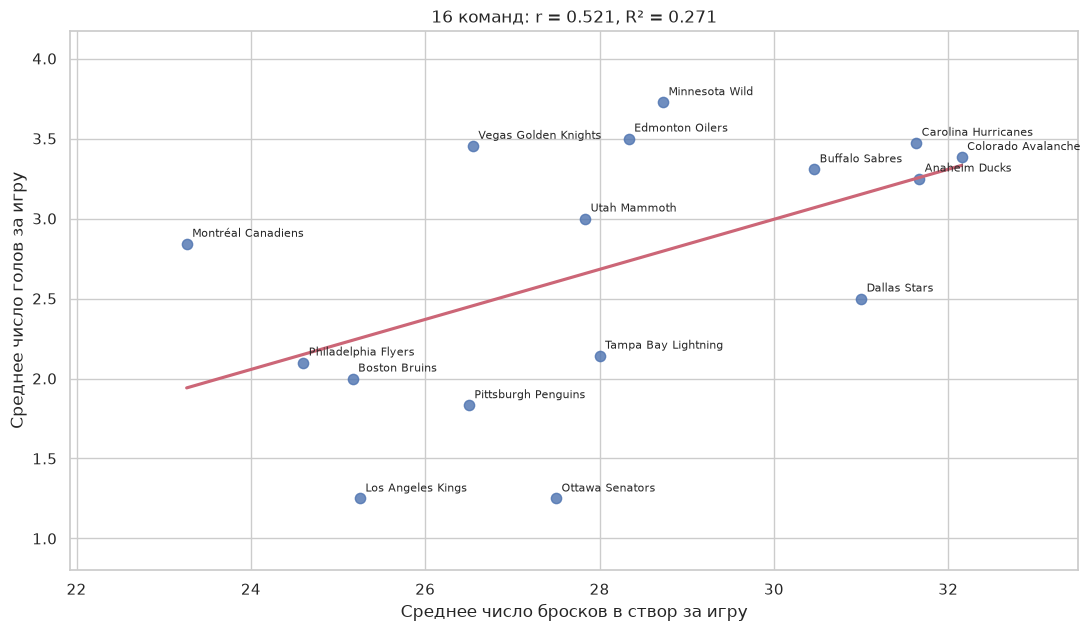

In [13]:
from scipy.stats import pearsonr

r, pvalue = pearsonr(avgshots["Shot"], avgshots["Goal"])
slope, intercept = np.polyfit(avgshots["Shot"], avgshots["Goal"], 1)

print(f"r = {r:.3f}; R² = {r*r:.3f}; наклон = {slope:.3f}")

plt.figure(figsize=(13, 7))
sns.regplot(
    data=avgshots, x="Shot", y="Goal", ci=None,
    scatter_kws={"s": 55},
    line_kws={"color": "#cc6677"},
)
for name, row in avgshots.iterrows():
    plt.annotate(
        name, (row["Shot"], row["Goal"]),
        xytext=(4, 5), textcoords="offset points", fontsize=8,
    )

plt.xlabel("Среднее число бросков в створ за игру")
plt.ylabel("Среднее число голов за игру")
plt.title(f"16 команд: r = {r:.3f}, R² = {r*r:.3f}")
plt.margins(x=0.15, y=0.18)
plt.savefig("figures/13_shots_goals_regression.svg", bbox_inches="tight")
plt.show()

### Результат и интерпретация

Корреляция Пирсона **r = 0.521**, коэффициент **R² = 0.271**.
Видна умеренная положительная линейная связь.

Команды, чаще бросавшие в створ, в среднем забивали больше.
При этом связь объясняет лишь часть различий: важны качество
моментов, реализация и соперники.

Это сравнение 16 команд, а не доказательство того, что дополнительный
бросок обязательно увеличивает число голов на фиксированную величину.

### 14. Найти матч с наибольшим числом всех бросков
### Идея решения

Учитываем четыре исхода: гол, отражённый бросок в створ,
промах и блок. Считаем число таких событий по каждой игре.

Ищем все игры с максимумом, чтобы не потерять возможные совпадения.

In [14]:
all_shot_types = [
    "goal", "shot-on-goal", "missed-shot", "blocked-shot"
]
all_shots = events.loc[
    events["Play Type"].isin(all_shot_types)
].copy()

attempts = all_shots.groupby("Game ID").size()
max_attempt_ids = attempts.index[attempts.eq(attempts.max())]

for gid in max_attempt_ids:
    print(gameInfo(gid), "— попыток:", attempts.loc[gid])

idxmax = max_attempt_ids[0]

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20) — попыток: 208


### Результат и интерпретация

Максимум — **208 попыток** — в матче
Carolina Hurricanes — Ottawa Senators: **3:2**, два овертайма,
20.04.2026.

 Два дополнительных периода увеличили время,
доступное для бросков. Здесь сравнивается общее число за игру,
а не количество попыток в минуту.

### 15. Изобразить броски на хоккейной площадке
### Идея решения

Используем `plot_rink` из приложенного файла.
Цвет точки показывает исход броска, форма — команду.

Чтобы хозяева всегда атаковали вправо, поворачиваем обе координаты
в периодах, где хозяева защищают правые ворота.
Для выбранного матча это нечётные периоды

Period
1    right
2     left
3    right
4     left
5    right
Name: Home Team's Defending Side, dtype: str

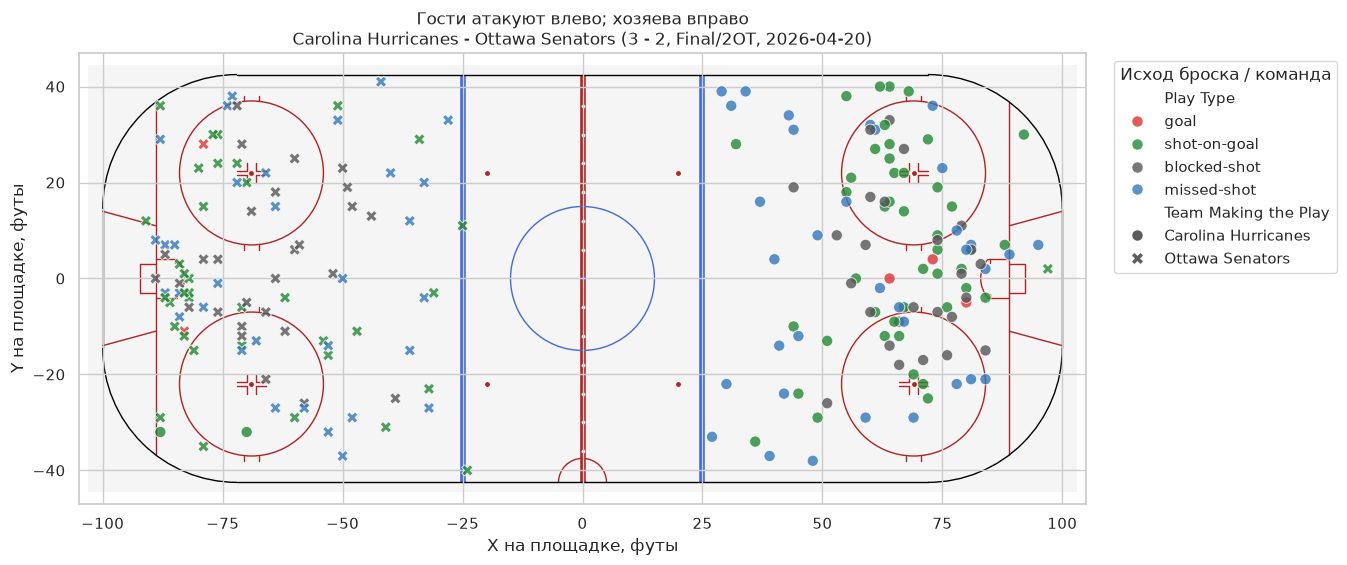

Проверено: направление ворот и команда всех 54 заблокированных бросков.


In [15]:
from rink import plot_rink

selected = all_shots.loc[all_shots["Game ID"].eq(idxmax)].copy()

display(
    selected.groupby("Period")["Home Team's Defending Side"].first()
)

flip = selected["Home Team's Defending Side"].eq("right")
selected["Plot X"] = selected[xcol] * np.where(flip, -1, 1)
selected["Plot Y"] = selected[ycol] * np.where(flip, -1, 1)

fig, ax = plt.subplots(figsize=(13, 6.8))
plot_rink()

sns.scatterplot(
    data=selected, x="Plot X", y="Plot Y",
    hue="Play Type", style="Team Making the Play",
    hue_order=["goal", "shot-on-goal", "blocked-shot", "missed-shot"],
    palette={
        "goal": "#dd3333",
        "shot-on-goal": "#228833",
        "blocked-shot": "#555555",
        "missed-shot": "#3377bb",
    },
    s=65, alpha=0.8, ax=ax,
)

ax.set_aspect("equal")
ax.set_xlim(-105, 105)
ax.set_ylim(-47, 47)
ax.set_xlabel("X на площадке, футы")
ax.set_ylabel("Y на площадке, футы")
ax.set_title("Гости атакуют влево; хозяева вправо\n" + gameInfo(idxmax))
ax.legend(
    title="Исход броска / команда",
    bbox_to_anchor=(1.02, 1), loc="upper left",
)
plt.savefig("figures/15_rink_shots.svg", bbox_inches="tight")
plt.show()

# Дополнительная проверка направления атаки и команды заблокированных бросков.
is_home = selected["Team Making the Play"].eq(selected["Home Team"])
goal_x = np.where(is_home.eq(selected["Home Team's Defending Side"].eq("left")), 89, -89)
assert np.array_equal(goal_x * np.where(flip, -1, 1), np.where(is_home, 89, -89))
for _, row in selected.loc[selected["Play Type"].eq("blocked-shot")].iterrows():
    side = "Home" if row["Team Making the Play"] == row["Home Team"] else "Away"
    names = row[[f"{side} Team's Player on the Ice #{i}" for i in range(1, 7)]].dropna()
    assert row["Player in the Event #2"] in names.to_list()
print("Проверено: направление ворот и команда всех 54 заблокированных бросков.")


### Результат и интерпретация

На площадке показаны **208 попыток**, включая **54 заблокированные**.
Гости атакуют левые ворота, хозяева — правые.

Для этой игры проверка сторон ворот:
поворачивать нужно нечётные периоды.
Для другого матча правило следует проверять заново.

Также проверено, что у заблокированных бросков
`Team Making the Play` соответствует бросавшей команде,
хотя первый участник события является блокирующим.

### 16. Найти десять игроков с наибольшим числом голов
### Идея решения

В событии `goal` первый участник является автором гола.
Считаем голы по имени игрока.

При равенстве показателя используем алфавитный порядок.
Он нужен для воспроизводимости и не означает спортивного преимущества.

In [16]:
def ranking(series, label, n=10):
    return (
        series.rename(label).rename_axis("Player").reset_index()
        .sort_values([label, "Player"], ascending=[False, True])
        .set_index("Player").head(n)
    )

player_goals = goals["Player in the Event #1"].value_counts()
top_goals = ranking(player_goals, "Goals")

display(top_goals)
assert player_goals.sum() == 486

,Goals
Player,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Jordan Staal,8
Nikolaj Ehlers,8
Alex Newhook,7
Jackson Blake,7
Mark Stone,7


### Результат и интерпретация

Лидер — **Brett Howden, 14 голов**.
В десятой строке таблицы — 7 голов; такой результат имеют
шесть игроков во всём наборе.

Выведено ровно десять строк. При равенстве голов место внутри
группы определяется алфавитом.

Это абсолютная результативность: у игроков команд, прошедших
дальше по турниру, было больше матчей.

### 17. Найти десять игроков с наибольшим числом голевых передач
### Идея решения

Ассистенты записаны во втором и третьем полях участников гола.
Объединяем эти поля, удаляем пропуски и считаем передачи.

У одного гола может быть ноль, один или два ассистента.

In [17]:
assist_names = (
    goals[["Player in the Event #2", "Player in the Event #3"]]
    .melt(value_name="Player")["Player"]
    .dropna()
)

player_assists = assist_names.value_counts()
top_assists = ranking(player_assists, "Assists")

display(top_assists)
print("Всего голевых передач:", player_assists.sum())

,Assists
Player,
Jack Eichel,20
Mitch Marner,19
Jackson Blake,13
Lane Hutson,13
Martin Necas,12
Nick Suzuki,12
Shea Theodore,12
Taylor Hall,12
Kirill Kaprizov,11


Всего голевых передач: 830


### Результат и интерпретация

Лидер — **Jack Eichel, 20 передач**.
Всего на 486 голов записано **830 голевых передач**.

Число передач может превышать число голов, поскольку за один гол
передачи могут получить два разных игрока.
Здесь учитываются именно голевые передачи, а не любые передачи шайбы.

### 18. Найти десять игроков с наибольшим числом очков «гол + пас»
### Идея решения

Складываем голы и передачи по именам.
Отсутствующий показатель заменяем нулём, чтобы не потерять игрока,
который только забивал или только ассистировал.

Для проверки выводим обе составляющие очков.

In [18]:
player_points = player_goals.add(
    player_assists, fill_value=0
).astype(int)

detail = pd.concat([
    player_goals.rename("Goals"),
    player_assists.rename("Assists"),
], axis=1).fillna(0).astype(int)

top_points = ranking(player_points, "Points").join(detail)
display(top_points)

assert player_points.sum() == (
    player_goals.sum() + player_assists.sum()
)

,Points,Goals,Assists
Player,,,
Mitch Marner,29,10,19
Jack Eichel,22,2,20
Jackson Blake,20,7,13
Taylor Hall,19,7,12
Brett Howden,18,14,4
Nikolaj Ehlers,18,8,10
Shea Theodore,18,6,12
Lane Hutson,16,3,13
Logan Stankoven,16,11,5


### Результат и интерпретация

Лидер — **Mitch Marner: 29 очков = 10 голов + 19 передач**.

Сумма очков всех игроков — **1 316**:
486 голов + 830 передач.

Один гол может принести очки нескольким игрокам, поэтому сумма
очков не равна числу голов.

### 19. Найти десять игроков с наибольшим средним числом бросков в створ
### Идея решения

Числитель — события `shot-on-goal` и `goal`, где игрок указан первым.
Знаменатель — все игры его участия по составам из пункта 7,
включая игры без бросков.

Деление только на игры с бросками завысило бы среднее.
Минимальное число матчей условием не задано, поэтому фильтр не вводим.

In [19]:
player_ngames = (
    appearances.groupby("Player")["Game ID"]
    .nunique().rename("Games")
)

accurate_events = shots.loc[shots["Accurate"]]
player_sog = (
    accurate_events["Player in the Event #1"]
    .value_counts().rename("Shots on Goal")
)

shot_rates = player_ngames.to_frame().join(player_sog).fillna(0)
shot_rates["Shots on Goal"] = shot_rates["Shots on Goal"].astype(int)
shot_rates["Per Game"] = (
    shot_rates["Shots on Goal"] / shot_rates["Games"]
)

top_shot_rates = ranking(shot_rates["Per Game"], "Per Game").join(
    shot_rates[["Shots on Goal", "Games"]]
)
display(top_shot_rates)

,Per Game,Shots on Goal,Games
Player,,,
Jason Robertson,5.000000,30,6
Dylan Guenther,4.500000,27,6
Nikita Kucherov,4.428571,31,7
Matt Boldy,4.363636,48,11
Quinton Byfield,4.250000,17,4
Darren Raddysh,4.000000,28,7
Joel Eriksson Ek,4.000000,24,6
Alex Laferriere,3.750000,15,4
David Pastrnak,3.666667,22,6


### Результат и интерпретация

Лидер — **Jason Robertson**:
**30 бросков в створ / 6 игр = 5.000 броска за игру**.

В таблице каждого игрока показаны числитель и знаменатель.
Игры с нулём бросков включены.

Это среднее за матч, а не за 60 минут: точного игрового времени
данный набор не содержит.

### 20. Найти десять игроков с наибольшим средним числом силовых приёмов
### Идея решения

В событии `hit` первый участник выполняет силовой приём.
Считаем такие события и делим на все игры участия игрока.

Используем тот же знаменатель, что и в пункте 19.
Игры без силовых приёмов также учитываются.

In [20]:
hits = events.loc[events["Play Type"].eq("hit")]
player_hits = (
    hits["Player in the Event #1"]
    .value_counts().rename("Hits")
)

hit_rates = player_ngames.to_frame().join(player_hits).fillna(0)
hit_rates["Hits"] = hit_rates["Hits"].astype(int)
hit_rates["Per Game"] = hit_rates["Hits"] / hit_rates["Games"]

top_hit_rates = ranking(hit_rates["Per Game"], "Per Game").join(
    hit_rates[["Hits", "Games"]]
)
display(top_hit_rates)

assert hit_rates["Hits"].sum() == len(hits)

,Per Game,Hits,Games
Player,,,
Lawson Crouse,6.333333,38,6
Alex Turcotte,6.000000,6,1
Alexander Petrovic,6.000000,6,1
Yakov Trenin,5.666667,51,9
Dylan Cozens,5.500000,22,4
Vasily Podkolzin,5.333333,32,6
Carl Grundstrom,5.000000,15,3
Ivan Barbashev,5.000000,110,22
Marcus Foligno,5.000000,55,11


### Результат и интерпретация

Лидер — **Lawson Crouse**:
**38 / 6 = 6.333 силового приёма за игру**.

Всего учтён **5 621 силовой приём**.
Сумма индивидуальных счётчиков совпала с числом событий `hit`.

Показатель зависит от роли игрока и времени на льду.
Его нельзя считать общей оценкой качества игры.

### 21. Найти вратарей с хотя бы одним матчем без лично пропущенных голов
### Идея решения

Сначала создадим все пары «вратарь — матч», включая выходивших
на замену. Затем посчитаем лично пропущенные голы.

В данных есть две особенности:

1. У всех 22 решающих голов в овертайме полностью отсутствуют составы.
   Такие строки нельзя автоматически считать голами в пустые ворота.
2. На некоторых голевых записях уже указан другой вратарь:
   снимок может отражать замену после пропущенного гола.

В основном расчёте используем последнее наблюдаемое состояние
вратаря перед голом в том же периоде. Явное отсутствие вратаря
сохраняем: не заполняем его через `ffill`.

Допущение: между предыдущим событием и голом не было незаписанной
замены. Для проверки чувствительности отдельно считаем вариант
по вратарю из самой строки `goal`, исправляя только пропуски
у решающих голов овертайма.

Это широкое определение из условия, включающее неполные выходы,
а не заявление об официальных индивидуальных shutout NHL.

In [21]:
# Все вратари, фактически появлявшиеся в каждом матче.
goalie_parts = []
for side in ["Away", "Home"]:
    part = events[
        ["Game ID", f"{side} Team", f"{side} Team's Goalie"]
    ].rename(columns={
        f"{side} Team": "Team",
        f"{side} Team's Goalie": "Goalie",
    })
    goalie_parts.append(
        part.dropna(subset=["Goalie"]).drop_duplicates()
    )

goalie_base = (
    pd.concat(goalie_parts, ignore_index=True)
    .drop_duplicates()
)

# Последнее наблюдаемое состояние перед каждым событием.
ordered = events.sort_values(["Game ID", "Period", "Play ID"])
prior_goalies = (
    ordered.groupby(["Game ID", "Period"])[goalie_cols]
    .shift()
    .reindex(events.index)
)

home_scored = goals["Team Making the Play"].eq(goals["Home Team"])

goalie_before_goal = prior_goalies.loc[
    goals.index, "Away Team's Goalie"
].where(
    home_scored,
    prior_goalies.loc[goals.index, "Home Team's Goalie"],
)

attributed = goals[["Game ID", "Play ID"]].copy()
attributed["Goalie"] = goalie_before_goal

ga = (
    attributed.dropna(subset=["Goalie"])
    .groupby(["Game ID", "Goalie"])
    .size().rename("Goals Against")
)

goalie_results = (
    goalie_base.set_index(["Game ID", "Goalie"])
    .join(ga)
    .fillna({"Goals Against": 0})
    .reset_index()
)

zero_games = goalie_results.loc[
    goalie_results["Goals Against"].eq(0)
]
zero_summary = (
    zero_games.groupby("Goalie")["Game ID"]
    .nunique().rename("Games Without Goals Against")
)

display(zero_summary)
display(zero_games)

# Альтернативная трактовка: поле непосредственно в строке goal.
raw_goalie = goals["Away Team's Goalie"].where(
    home_scored, goals["Home Team's Goalie"]
)

ot_missing = (
    goals["Period"].gt(3)
    & goals[roster_cols].isna().all(axis=1)
)
alternative_goalie = raw_goalie.copy()
alternative_goalie.loc[ot_missing] = goalie_before_goal.loc[ot_missing]

alternative_ga = (
    goals[["Game ID"]]
    .assign(Goalie=alternative_goalie)
    .dropna(subset=["Goalie"])
    .groupby(["Game ID", "Goalie"])
    .size()
)

alternative = goalie_base.set_index(["Game ID", "Goalie"]).copy()
alternative["Goals Against"] = alternative_ga.reindex(
    alternative.index, fill_value=0
)
alternative_names = set(
    alternative.loc[alternative["Goals Against"].eq(0)]
    .reset_index()["Goalie"]
)

print("Основной список:", sorted(zero_summary.index))
print("Альтернативный список:", sorted(alternative_names))

Goalie
Alex Lyon               1
Andrei Vasilevskiy      1
Brandon Bussi           1
Dan Vladar              2
Frederik Andersen       3
Joonas Korpisalo        1
Scott Wedgewood         1
Ukko-Pekka Luukkonen    1
Name: Games Without Goals Against, dtype: int64

,Game ID,Goalie,Team,Goals Against
11,2025030126,Andrei Vasilevskiy,Tampa Bay Lightning,0.0
18,2025030142,Dan Vladar,Philadelphia Flyers,0.0
52,2025030216,Ukko-Pekka Luukkonen,Buffalo Sabres,0.0
73,2025030314,Frederik Andersen,Carolina Hurricanes,0.0
85,2025030416,Brandon Bussi,Carolina Hurricanes,0.0
88,2025030112,Alex Lyon,Buffalo Sabres,0.0
91,2025030114,Joonas Korpisalo,Boston Bruins,0.0
101,2025030131,Frederik Andersen,Carolina Hurricanes,0.0
110,2025030146,Dan Vladar,Philadelphia Flyers,0.0
142,2025030221,Frederik Andersen,Carolina Hurricanes,0.0


Основной список: ['Alex Lyon', 'Andrei Vasilevskiy', 'Brandon Bussi', 'Dan Vladar', 'Frederik Andersen', 'Joonas Korpisalo', 'Scott Wedgewood', 'Ukko-Pekka Luukkonen']
Альтернативный список: ['Andrei Vasilevskiy', 'Brandon Bussi', 'Dan Vladar', 'Frederik Andersen', 'Joonas Korpisalo', 'Scott Wedgewood']


### Результат и интерпретация

Основной метод даёт **8 вратарей** и **11 пар «вратарь — матч»**:

- Alex Lyon — **1**
- Andrei Vasilevskiy — **1**
- Brandon Bussi — **1**
- Dan Vladar — **2**
- Frederik Andersen — **3**
- Joonas Korpisalo — **1**
- Scott Wedgewood — **1**
- Ukko-Pekka Luukkonen — **1**

В четырёх таких выходах команда всё же пропускала.
Поэтому отбор только командных сухих матчей потерял бы часть
подходящих случаев.

При альтернативном использовании вратаря из строки goal,
с восстановлением пропусков овертайма, остаётся **6 вратарей**:
из списка исчезают Alex Lyon и Ukko-Pekka Luukkonen.

Различие связано с моментом замены на голевой записи.
Основной метод относит гол последнему наблюдавшемуся вратарю
до события. Данные не содержат точных смен, поэтому зависимость
ответа от этого допущения показана явно.

Без исправления пустых составов овертайма в список ошибочно
попали бы Arturs Silovs и Jakub Dobes, пропустившие решающие голы.

В выводе показаны 11 подходящих пар «вратарь — матч»,
основной и альтернативный списки вратарей.
Расчёт обоих вариантов приведён в коде.

### 22. Собственный вопрос: как связана дистанция с долей голов?
### Идея решения

Разделим незаблокированные броски на диапазоны расстояний.
В каждом посчитаем число попыток, голов и отношение голов к попыткам.

Отдельно рассмотрим броски при указанном вратаре и без него.
Для голевых событий используем предшествующий вратарский контекст
из пункта 21. Это помогает не смешивать дальние броски в пустые
ворота с бросками при вратаре.

Attempts  Goals  Goal Share
Distance Group Goalie Status                                   
0–15           Вратарь отсутствует         3      3    1.000000
               Вратарь указан           1745    200    0.114613
15–30          Вратарь отсутствует         6      6    1.000000
               Вратарь указан           1651    134    0.081163
30–60          Вратарь отсутствует        11      6    0.545455
               Вратарь указан           2973    108    0.036327
60–90          Вратарь отсутствует        13      4    0.307692
               Вратарь указан            624      8    0.012821
90+            Вратарь отсутствует        38     15    0.394737
               Вратарь указан            202      2    0.009901

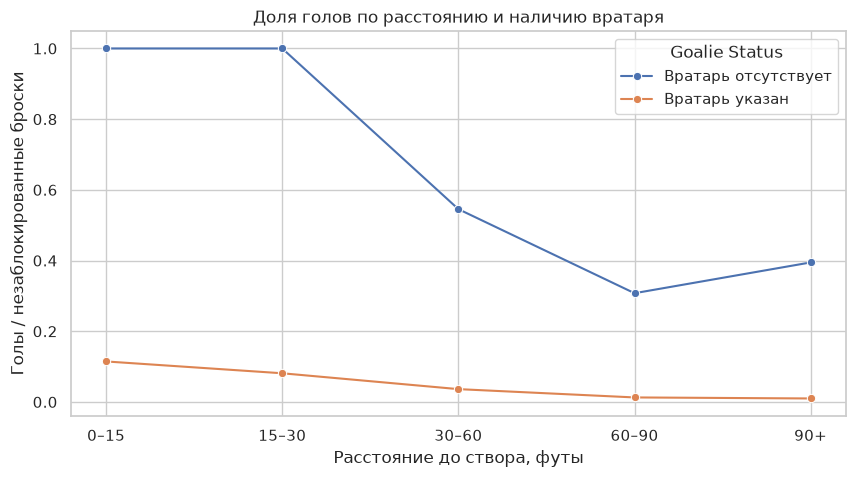

In [22]:
# У неголевых бросков используем поле события.
# У голов — последнее наблюдаемое состояние до гола.
shots["Opponent Goalie"] = shots["Away Team's Goalie"].where(
    shots["Team Making the Play"].eq(shots["Home Team"]),
    shots["Home Team's Goalie"],
)
shots.loc[goals.index, "Opponent Goalie"] = goalie_before_goal

shots["Distance Group"] = pd.cut(
    shots["Shot Length"],
    bins=[0, 15, 30, 60, 90, np.inf],
    labels=["0–15", "15–30", "30–60", "60–90", "90+"],
    right=False,
)
shots["Goalie Status"] = np.where(
    shots["Opponent Goalie"].notna(),
    "Вратарь указан",
    "Вратарь отсутствует",
)
shots["Is Goal"] = shots["Play Type"].eq("goal")

conversion = shots.groupby(
    ["Distance Group", "Goalie Status"], observed=False
).agg(
    Attempts=("Is Goal", "size"),
    Goals=("Is Goal", "sum"),
)
conversion["Goal Share"] = (
    conversion["Goals"]
    / conversion["Attempts"].replace(0, np.nan)
)
display(conversion)

plot_data = conversion.reset_index()
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=plot_data, x="Distance Group", y="Goal Share",
    hue="Goalie Status", marker="o",
)
plt.xlabel("Расстояние до створа, футы")
plt.ylabel("Голы / незаблокированные броски")
plt.title("Доля голов по расстоянию и наличию вратаря")
plt.savefig("figures/22_distance_conversion.svg", bbox_inches="tight")
plt.show()

assert conversion["Attempts"].sum() == 7266
assert conversion["Goals"].sum() == 486

### Результат и интерпретация

При указанном вратаре:

- С 0–15 футов: **200 голов / 1 745 попыток = 11.5%**.
- С 90+ футов: **2 гола / 202 попытки = 1.0%**.

В этих группах близкие незаблокированные броски заметно чаще
заканчивались голом. Отсутствие вратаря существенно меняет контекст
дальних попыток, поэтому группы рассматриваются отдельно.

В группах без вратаря на расстояниях 0–15 и 15–30 футов всего 3 и 6 попыток. Доля 100% в таких малых группах не означает, что любой следующий бросок обязательно закончится голом. График показывает наблюдаемые доли. Доверительные интервалы не строились.

Это описание учебного набора. Без учёта угла, типа атаки,численного состава и других факторов результат нельзя считать моделью ожидаемых голов или доказательством влияния одной дистанции.